<Body>   
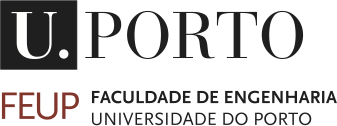   
<h1> <b>Swarm Robotics Competitions 2025/2026 </b> </h1>
</Body>  

**A. Pedro Aguiar** (pedro.aguiar@fe.up.pt)

**José P. Carvalho** (jpcarvalho@fe.up.pt)

FEUP, Oct. 2025

---


The objective of this Colab notebook is to provide an introduction to Python programming within the context of control systems. We will cover basic Python syntax, essential libraries for control systems, and a simple example to illustrate the concepts.




# 1- What is Colaboratory?
(*This section is a partially copy of the "Colab getting started" file.*)





Colaboratory, or "Colab" for short, allows you to write and execute Python in your browser, with
- Zero configuration required
- Free access to GPUs
- Easy sharing


The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code.

For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut **"Command/Ctrl+Enter"**. To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

# 2 - Resources

*In this course you don't need to know much more than what is presented here, but if you are interested, here goes a list of references where you can find more information about jupyter notebooks and Python.*

* Jupyter notebook:
https://jupyter.org

* The Markdown Guide: https://www.markdownguide.org

* Introduction to Python (a collection of notebooks):
https://nbviewer.jupyter.org/github/ehmatthes/intro_programming/blob/master/notebooks/contents.ipynb

* A Crash Course in Python for Scientists:
https://nbviewer.jupyter.org/gist/rpmuller/5920182

* Scientific Computing with Python:
https://nbviewer.jupyter.org/url/atwallab.cshl.edu/teaching/QBbootcamp3.ipynb

* For users who are more familiar with Matlab, check here a comparison of NumPy and analog functions in Matlab:
https://numpy.org/devdocs/user/numpy-for-matlab-users.html


# 3 - Useful libraries: a quickstart

*You can skip this section, this is just for who may be interested about Python*.

Some interesting and useful Python libraries:


__Numpy__

NumPy is the fundamental package for scientific computing with Python.
<br> NumPy user guide: https://numpy.org/doc/stable/user/index.html

__Scipy__

The SciPy library is a collection of numerical algorithms and domain-specific toolboxes, including signal processing, optimization, statistics and much more.
<br> Scipy user guide: https://scipy.github.io/devdocs/tutorial/index.html#user-guide

__Matplotlib__

Matplotlib is a python 2D plotting library which produces publication quality figures in a variety of hardcopy formats and interactive environments across platforms.
<br> Matplotlib user guide: https://matplotlib.org/stable/contents.html

__Sympy__

SymPy is a Python library for symbolic mathematics.
<br> SymPy tutorial: https://docs.sympy.org/latest/tutorial/index.html#tutorial



**1.1 Variables and data types**


In [ ]:
a = 5
b = 3.14
c = 'MPSAC'

print(a)
print(b)
print(c)
print(a+b)
print(c,5)

**1.2 Lists and Loops**

In [ ]:
numbers = [1, 2, 3, 4, 5]

for number in numbers:
    print(number)



It's also possible to do C-like syntax

In [ ]:
for i in range(len(numbers)):
  print(numbers[i])

**1.3 Functions and Conditions**

*Intro to Numpy*

In [ ]:
import numpy as np
np.zeros(5)

In [ ]:
def is_equal(a,b):
  if a==b:
    return True
  else:
    return False

In [ ]:
print(is_equal('MPSAC','CSR'))
print(is_equal(2,2))

It's possible to use np.array() to transform a list into a vector/matrix

In [ ]:
vec = np.array(numbers)

print(vec)

The operator @ is used to multiply matrices

In [ ]:
x = vec @ np.transpose(vec)
y = vec * vec
print(x)
print(y)

## What is a control system?

<Body>   
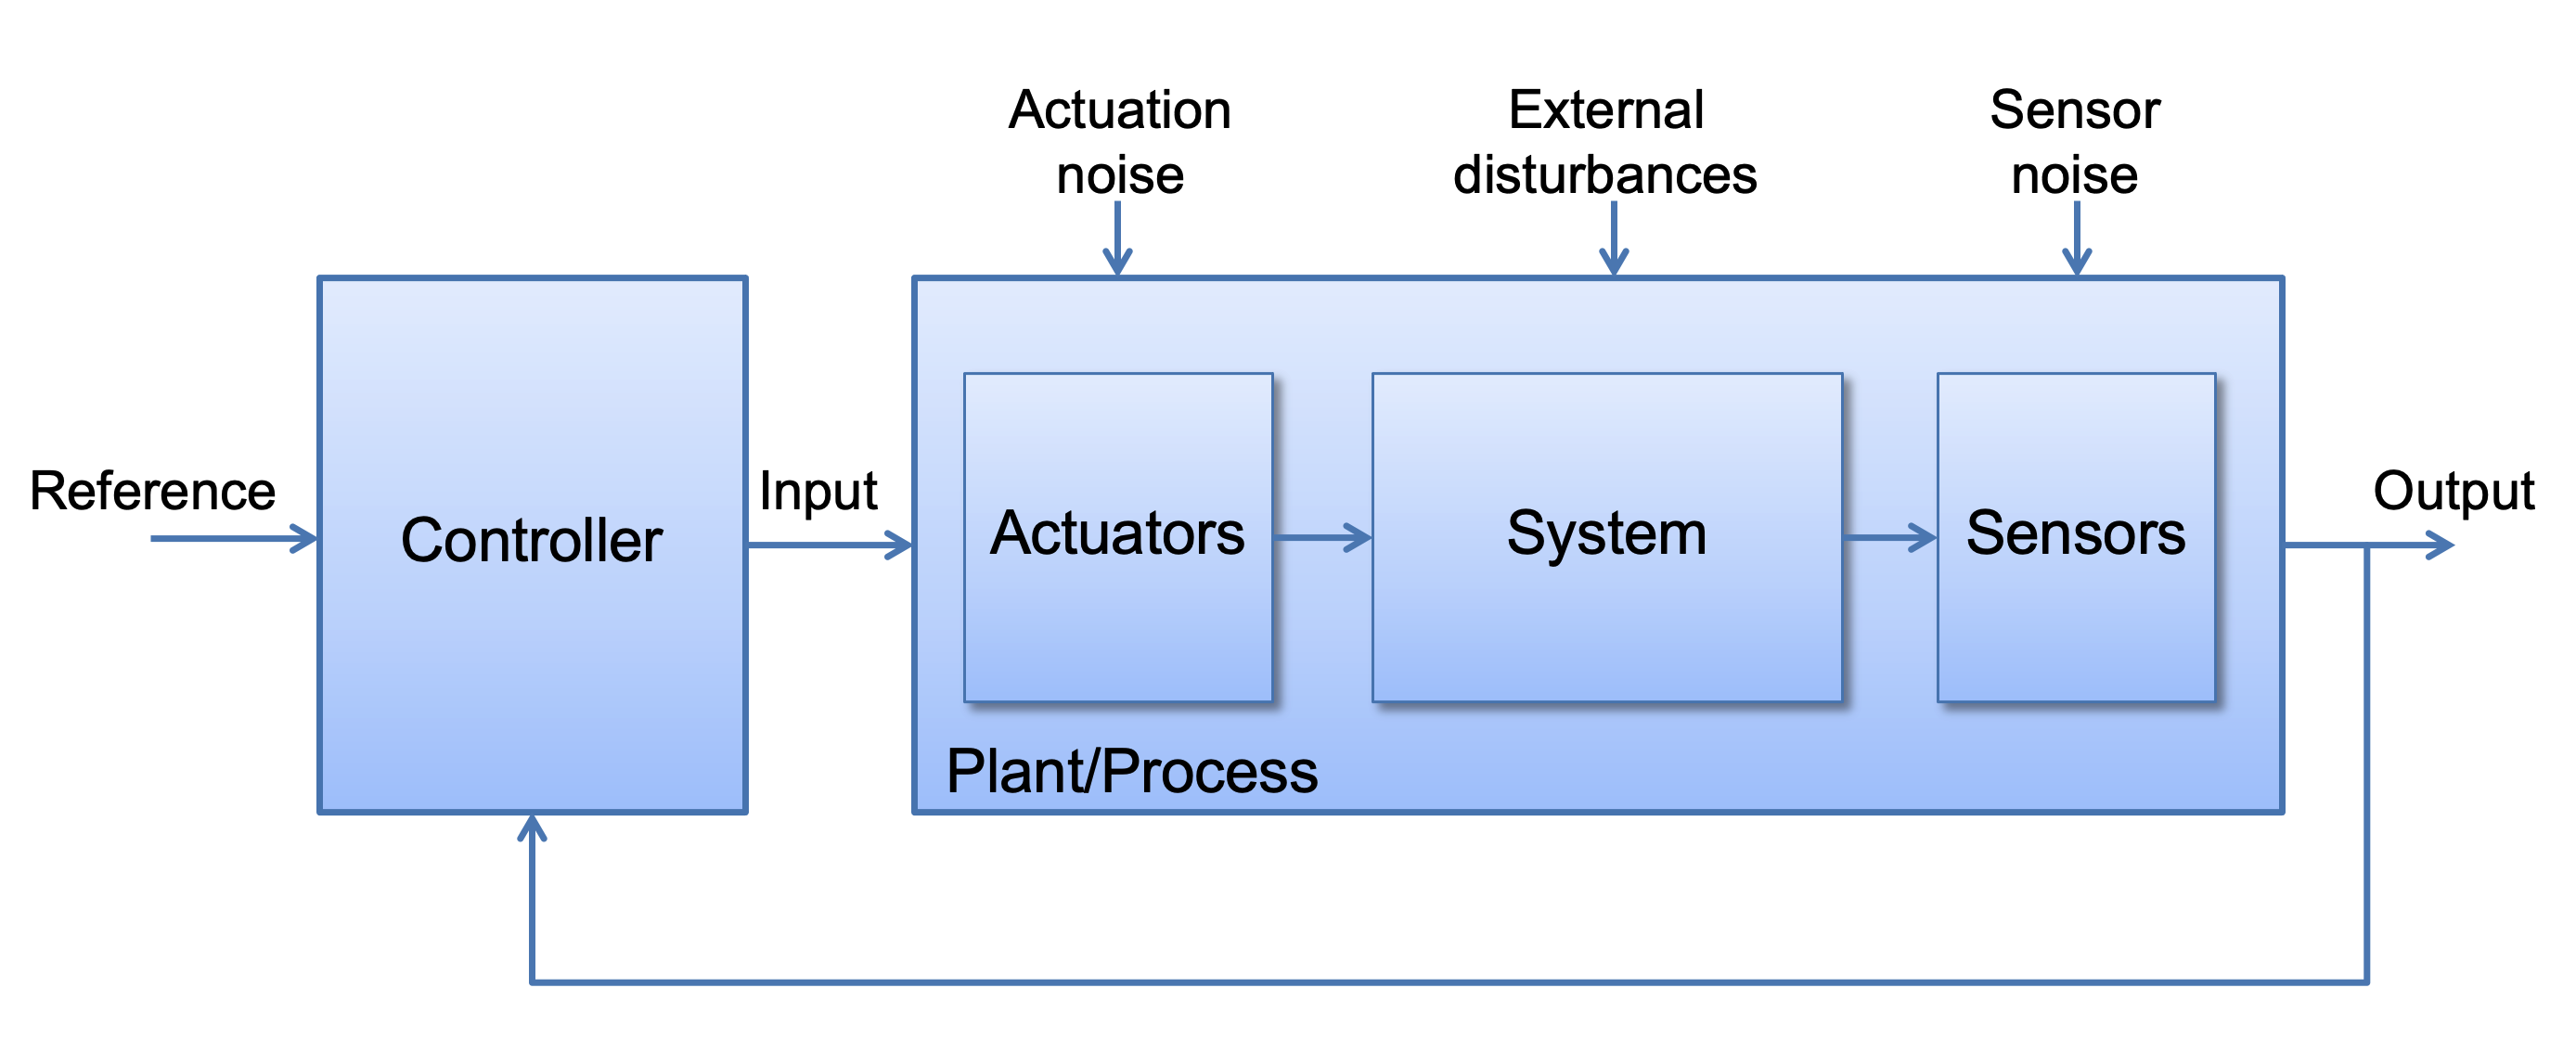


### Control Problem:

Design a controller (algorithm) that in **real-time** stabilizes the plant, and make the output signal to track the reference despite external disturbances, noises, and uncertainty.

*In our case the system is a single integrator.*



### The single integrator dynamics


Consider the following dynamical system
$$
\dot x=u
$$
where $x(t)\in\mathbf{R}$ is the state and $u(t)\in\mathbf{R}$ is the input signal, and $\dot x$ denotes the derivative with respect to time $t$, that is, $\dot x = \frac{d x(t)}{dt}$

We can think $x$ as the position and $u$ as the velocity (which in this case is your command).


Let's now see how it evolves in time as a function of the input $u(t)$.

For this end, we will numerically solve  the ODE (ordinary differencial equation)!

A simple approach is to use the **Euler discretization** to approximate the solution of a continuous time differential equation
https://en.wikipedia.org/wiki/Euler_method

That is,
$$
\frac{d x(t)}{dt} \approx \frac{x(t+h)-x(t)}{h}
$$
where $h \ge 0$ is the step size.

It turns out that for a step size sufficiently small, we can obtain a very good approximation.





In our case, we obtain

$$
\frac{x(t+h)-x(t)}{h} \approx u(t)
$$

By denoting $x_i=x(t_i)$ and $x_{i+1}=x(t_i + h)$, after some simple mathematical manipulation, we obtain the *discrete system*

$$
x_{i+1} = x_i + h\, u_i, \quad i = 0, 1, 2, \ldots
$$


Let's now show the results through simulation by plotting the (approximated) **time-evolution** of the state $x(t)$ and the control signal $u(t)$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def step_f(x,u,h):
  return x + u*h

h = 0.01 # This is my sampling time
t_end=10 # This is my final time of the simulation

t_signal = np.arange(0,t_end,h) # time samples
x_signal = np.zeros_like(t_signal)
u_signal = np.zeros_like(t_signal)

#Initial conditions of our system
x_signal[0] = 0

# Iteration
for i in range(0,t_signal.shape[0]-1):
#    u_signal[i] = 1
    if t_signal[i]<5:
      u_signal[i] = 1
    else:
      u_signal[i] = 0
    x_signal[i+1] = step_f(x_signal[i],u_signal[i],h)

#plot
fig = plt.figure(figsize=(15,5))
fig.subplots_adjust(wspace = 0.5, hspace = 0.5)
ax1 = fig.add_subplot(2,1,1)
ax2 = fig.add_subplot(2,1,2)


ax1.plot(t_signal, x_signal, 'r-', label='$x(t)$')
ax1.set_title("Single integrator")
ax1.set_xlabel("time [s]")
ax1.grid()
ax1.legend(loc='best')

ax2.plot(t_signal[0:len(t_signal)-1], u_signal[0:len(t_signal)-1], 'b-', label='$u(t)$')
ax2.set_ylim((0, 1.2))
ax2.set_title("Control signal")
ax2.set_xlabel("time [s]")
ax2.grid()
ax2.legend(loc='best')



### **Simulating another system using numpy**


In [ ]:

# Constants
g = 9.81  # Acceleration due to gravity (m/s^2)
mu_k = 0.1  # Coefficient of kinetic friction
m = 1 # mass
theta = np.radians(30)  # Slope angle in radians
time_step = 0.01  # Time step for simulation
total_time = 5  # Total simulation time




In [ ]:
# Simulation
time = np.arange(0, total_time, time_step) #[0, 0.01, ... ,5]
num_steps = len(time)

# Arrays to store position and velocity values
x_values = np.zeros((2,num_steps)) # vector with zeros, position and speed


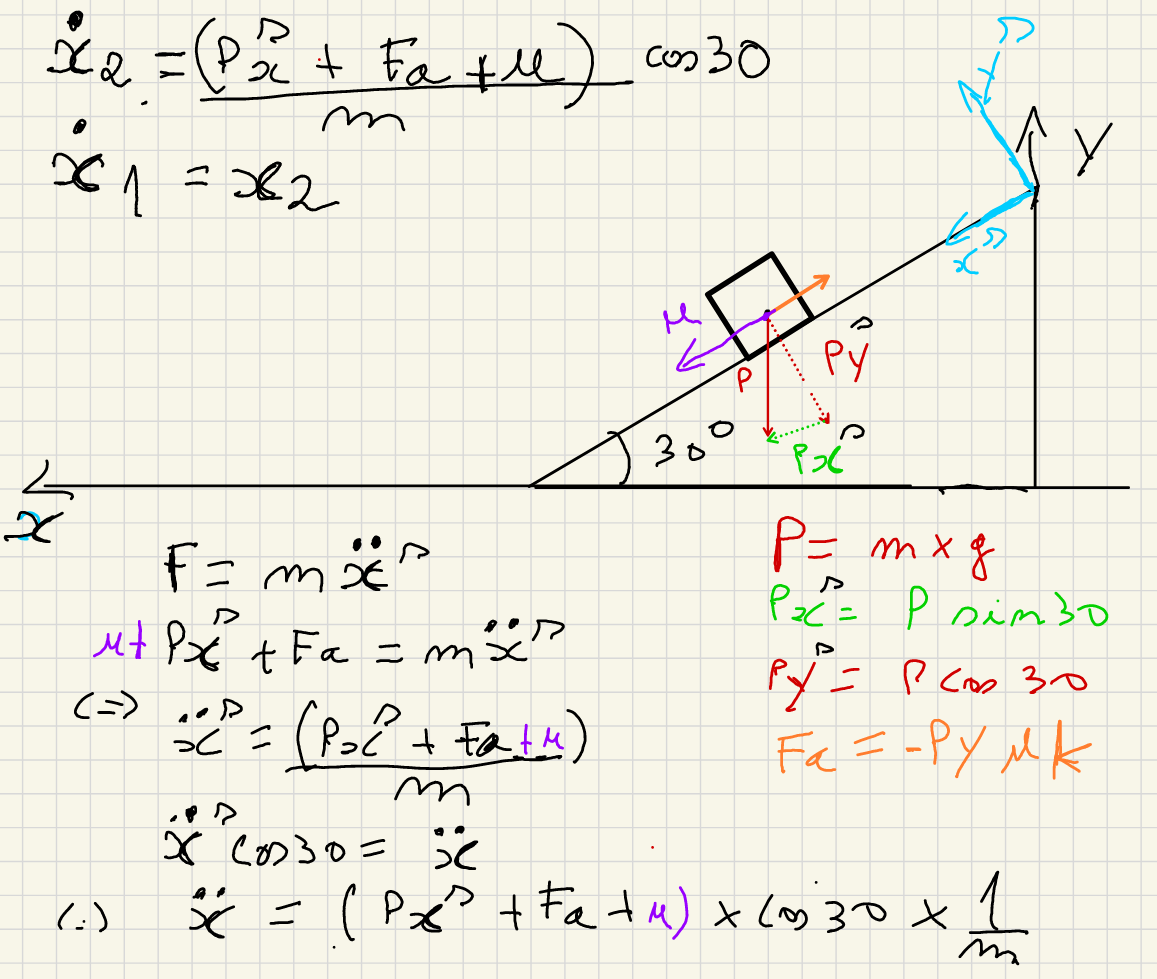

Let the system be described by:
$$
\dot{x} =
\begin{cases}
\dot{x}_2 &= \frac{(P_x^s + F_a + u)}{m}\cos(30)\\
\dot{x}_1 &= x_2
\end{cases}
$$

In [ ]:
def simulation_step(t,x,u,g,mu_k,theta,m,time_step):
    # Gravity force component along the slope
    F_gravity = -g * m * np.sin(theta)
    # Friction force
    F_friction = mu_k * g * m * np.cos(theta)
    if x[0] <=0:
      F_friction = -mu_k * g * x[1] # to make the box stop
      F_gravity = 0

    # Net force
    F_net = F_gravity + F_friction + u

    # Acceleration
    a = F_net/m *np.cos(theta)

    # Update velocity and position using numerical integration (Euler's method)

    x[1] += a * time_step
    x[0] += x[1] * time_step

    return x[0] , x[1]


In [ ]:
x = 10 #initial conditions
v = 0
u=0
for t in range(num_steps):
  state = [x,v]
  x , v = simulation_step(time[t],state,u,g,mu_k,theta,m,time_step)
  x_values[0,t]= x
  x_values[1,t] = v

In [ ]:
import matplotlib.pyplot as plt

plt.plot(time, x_values[0], label='Position (m)')
plt.plot(time, x_values[1], label='Velocity (m/s)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid(True)
plt.title('Block Sliding Down a Slope Simulation')
plt.show()

In [ ]:
def get_y(x):
    # Convert the angle to radians
    slope_angle_rad = np.radians(30)

    # Calculate the y value on the sliding slope
    y = np.zeros(len(x))
    for i in range(len(x)):
      if x[i]>=0:
        y[i] = np.tan(slope_angle_rad) * (x[i] - 10)
      else:
        y[i]=np.tan(slope_angle_rad) * (0 - 10)

    return y

# Define the slope parameters
start_x = 10
end_x = 0
slope_angle = 30  # in degrees

# Convert the angle to radians
slope_angle_rad = np.radians(slope_angle)

# Calculate the slope length and corresponding y values
slope_length = start_x / np.cos(slope_angle_rad)
x_values_slope = np.linspace(start_x, end_x, num=100)
y_values_slope = np.tan(slope_angle_rad) * (x_values_slope - start_x)

# Calculate the y value of the ground at x=0
ground_y_at_zero = get_y(np.zeros(1))
y_box= get_y(x_values[0])

# Plot the sliding slope with reduced transparency after x=0
plt.plot(x_values_slope, y_values_slope, label='Sliding Slope')
plt.scatter(x_values[0],y_box,label='box',color='black')
# Plot the ground after the slope
plt.axhline(ground_y_at_zero, color='black', linestyle='--', label='Ground')

# Add labels and title
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Sliding Slope with 30-degree Angle')
plt.legend()

# Remove y-axis values
plt.yticks([])
plt.xlim([-5, 10])
# Show the plot
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def get_y(x, slope_angle_rad):
    y = np.zeros(len(x))
    for i in range(len(x)):
        if x[i] >= 0:
            y[i] = np.tan(slope_angle_rad) * (x[i] - 10)
        else:
            y[i] = np.tan(slope_angle_rad) * (0 - 10)
    return y

def update(frame):
    ax.clear()

    # Plot the sliding slope with reduced transparency after x=0
    x_values_slope = np.linspace(start_x, end_x, num=100)
    y_values_slope = np.tan(slope_angle_rad) * (x_values_slope - start_x)
    ax.plot(x_values_slope, y_values_slope, label='Sliding Slope')

    # Plot the box
    box_x = x_values[0][frame]
    box_y = get_y(np.array([box_x]), slope_angle_rad)
    ax.scatter(box_x, box_y, label='Box', color='black')

    # Plot the ground after the slope
    ground_y_at_zero = get_y(np.zeros(1), slope_angle_rad)
    ax.axhline(ground_y_at_zero, color='black', linestyle='--', label='Ground')

    # Add labels and title
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')
    ax.set_title(f'Sliding Slope Animation (Frame {frame + 1})')
    ax.legend()

    # Remove y-axis values
    ax.set_yticks([])
    ax.set_xlim([-5, 10])
    ax.grid(True)


# Set up the plot
fig, ax = plt.subplots()

# Create the animation
animation = FuncAnimation(fig, update, frames=len(x_values[0]), interval=100)

# Display the animation
from IPython.display import HTML
HTML(animation.to_jshtml())

Let's control the block

In [ ]:


time = np.arange(0, total_time, time_step) #[0, 0.01, ... ,5]
num_steps = len(time)

# Arrays to store position and velocity values
x_values = np.zeros((2,num_steps)) # vector with zeros, position and speed

x = 0 #initial conditions
v = 0
u=0
x_ref= 5
kp=5
kv=1
for t in range(num_steps):
  state = [x,v]
  error_p= x-x_ref
  v_ref= -kv*error_p
  u= -kp*(v-v_ref) - (-g * m * np.sin(theta)) -(mu_k * g * m * np.cos(theta))


  x , v = simulation_step(time[t],state,u,g,mu_k,theta,m,time_step)
  x_values[0,t]= x
  x_values[1,t] = v


In [ ]:
plt.plot(time, x_values[0], label='Position (m)')
plt.plot(time, x_values[1], label='Velocity (m/s)')
plt.xlabel('Time (s)')
plt.legend()
plt.grid(True)
plt.title('Block Sliding Down a Slope Simulation')
plt.show()

In [ ]:
fig, ax = plt.subplots()

# Create the animation
animation = FuncAnimation(fig, update, frames=len(x_values[0]), interval=100)

# Display the animation
from IPython.display import HTML
HTML(animation.to_jshtml())